# Human Age Estimation with Deep Learning

Three models are trained on UTKFace and compared on the same test set:

1. **CNN** – custom CNN (grayscale) with augmentation, Huber loss and early stopping
2. **CNN + GAN** – the same CNN, trained with extra faces generated by a conditional GAN
3. **EfficientNetB0** – transfer learning from ImageNet (RGB)

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, optimizers, callbacks

SEED = 42
IMG_SIZE = 128
MAX_AGE = 90
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices('GPU'))

I0000 00:00:1791981700.629971     480 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791981702.895422     480 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Data

Grayscale: (23621, 128, 128, 1) | RGB: (23621, 128, 128, 3)
Train: 17006 | Val: 1890 | Test: 4725


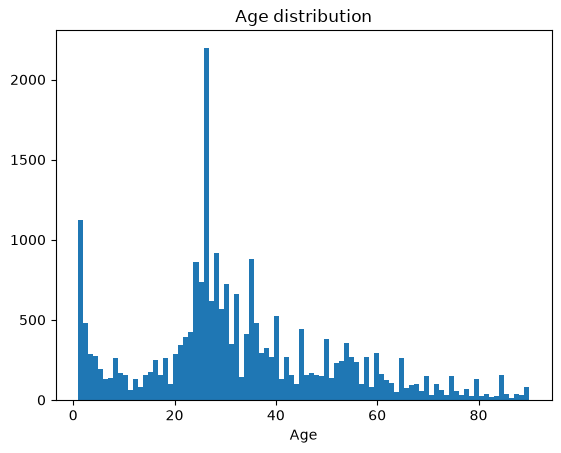

In [2]:
# Path to the UTKFace folder (override with the UTKFACE_DIR environment variable)
image_dir = os.environ.get("UTKFACE_DIR", "UTKFace")

gray_images, rgb_images, ages = [], [], []
for filename in sorted(os.listdir(image_dir)):
    if filename.endswith(".jpg"):
        try:
            age = int(filename.split("_")[0])
            if 0 <= age <= MAX_AGE:
                img = cv2.imread(os.path.join(image_dir, filename))
                img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
                gray_images.append(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY))
                rgb_images.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
                ages.append(age / MAX_AGE)
        except Exception as e:
            print(f"Skipping {filename}: {e}")

# Images are kept as uint8 (0-255); every model rescales internally
x_gray = np.expand_dims(np.array(gray_images, dtype=np.uint8), axis=-1)
x_rgb = np.array(rgb_images, dtype=np.uint8)
y = np.array(ages, dtype=np.float32)
del gray_images, rgb_images

# 80% train / 20% test, then 10% of train for validation (early stopping)
idx = np.arange(len(y))
train_idx, test_idx = train_test_split(idx, test_size=0.2, random_state=SEED)
train_idx, val_idx = train_test_split(train_idx, test_size=0.1, random_state=SEED)

x_gray_train, x_gray_val, x_gray_test = x_gray[train_idx], x_gray[val_idx], x_gray[test_idx]
x_rgb_train, x_rgb_val, x_rgb_test = x_rgb[train_idx], x_rgb[val_idx], x_rgb[test_idx]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]

print("Grayscale:", x_gray.shape, "| RGB:", x_rgb.shape)
print(f"Train: {len(y_train)} | Val: {len(y_val)} | Test: {len(y_test)}")

plt.hist(y * MAX_AGE, bins=MAX_AGE)
plt.title("Age distribution")
plt.xlabel("Age")
plt.show()

In [3]:
def denormalize_age(normalized_age):
    return normalized_age * MAX_AGE

def make_dataset(x, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(5000, seed=SEED)
    return ds.batch(BATCH_SIZE) \
        .map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=AUTOTUNE) \
        .prefetch(AUTOTUNE)

def augmentation():
    # Active only during training
    return models.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.05, 0.05),
        layers.RandomContrast(0.2),
        layers.RandomBrightness(0.2, value_range=(0, 255)),
    ], name="augmentation")

def training_callbacks(patience=8):
    return [
        callbacks.EarlyStopping(monitor="val_mae", patience=patience, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5, patience=3, min_lr=1e-6),
    ]

def plot_history(history, title):
    plt.plot(denormalize_age(np.array(history["mae"])), label="train")
    plt.plot(denormalize_age(np.array(history["val_mae"])), label="validation")
    plt.title(f"{title} - MAE (years)")
    plt.xlabel("Epoch")
    plt.legend()
    plt.show()

AGE_GROUPS = [(0, 12), (13, 19), (20, 29), (30, 39), (40, 49), (50, 59), (60, 90)]

def evaluate_model(model, x, y_true_norm):
    y_true = denormalize_age(y_true_norm)
    y_pred = denormalize_age(model.predict(x.astype(np.float32), batch_size=64, verbose=0).ravel())
    err = np.abs(y_pred - y_true)
    groups = {f"{lo}-{hi}": err[(y_true >= lo) & (y_true <= hi)].mean() for lo, hi in AGE_GROUPS}
    return {"MAE": err.mean(), "RMSE": np.sqrt(((y_pred - y_true) ** 2).mean()), "groups": groups}

## 2. Model 1 – CNN (without GAN)

Epoch 1/50


/root/age/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


532/532 - 46s - 86ms/step - loss: 0.0184 - mae: 0.2280 - val_loss: 0.0248 - val_mae: 0.2960 - learning_rate: 0.0010


Epoch 2/50


532/532 - 38s - 72ms/step - loss: 0.0095 - mae: 0.1366 - val_loss: 0.0164 - val_mae: 0.2093 - learning_rate: 0.0010


...

532/532 - 39s - 73ms/step - loss: 0.0045 - mae: 0.0793 - val_loss: 0.0034 - val_mae: 0.0689 - learning_rate: 1.5625e-05


Epoch 37/50


532/532 - 38s - 72ms/step - loss: 0.0044 - mae: 0.0782 - val_loss: 0.0033 - val_mae: 0.0675 - learning_rate: 7.8125e-06


Epoch 38/50


532/532 - 38s - 72ms/step - loss: 0.0044 - mae: 0.0785 - val_loss: 0.0033 - val_mae: 0.0679 - learning_rate: 7.8125e-06


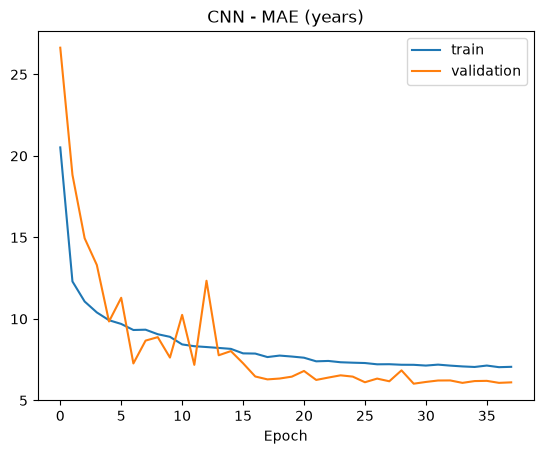

In [4]:
def build_cnn():
    inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = augmentation()(inp)
    x = layers.Rescaling(1.0 / 255)(x)
    for filters in [32, 64, 128, 256, 512]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(1)(x)

    model = models.Model(inp, out)
    # Huber is less sensitive to outliers than MSE (delta 0.1 ≈ 9 years)
    model.compile(optimizer=optimizers.Adam(1e-3), loss=tf.keras.losses.Huber(delta=0.1), metrics=["mae"])
    return model

cnn_model = build_cnn()
cnn_history = cnn_model.fit(
    make_dataset(x_gray_train, y_train, training=True),
    validation_data=make_dataset(x_gray_val, y_val),
    epochs=50,
    callbacks=training_callbacks(),
    verbose=2,
)
plot_history(cnn_history.history, "CNN")
cnn_model.save("age_cnn.keras")

## 3. Conditional GAN

Both networks receive the age. The discriminator uses the age twice: as an extra input channel and through a
projection term (Miyato & Koyama, 2018), which pushes the generator to produce faces that match the requested age.

In [5]:
NOISE_DIM = 100
GAN_BATCH_SIZE = 64
EPOCHS_GAN = 30

def build_generator():
    noise = layers.Input(shape=(NOISE_DIM,))
    age = layers.Input(shape=(1,))
    age_emb = layers.Dense(64, activation="relu")(age)

    x = layers.Concatenate()([noise, age_emb])
    x = layers.Dense(8*8*256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)
    x = layers.Reshape((8, 8, 256))(x)
    # Age is injected again as a feature map
    age_map = layers.Reshape((8, 8, 16))(layers.Dense(8*8*16)(age_emb))
    x = layers.Concatenate()([x, age_map])

    for filters in [128, 64, 32]:                      # 16x16 -> 32x32 -> 64x64
        x = layers.Conv2DTranspose(filters, 5, strides=2, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.LeakyReLU()(x)

    out = layers.Conv2DTranspose(1, 5, strides=2, padding="same", activation="tanh")(x)  # 128x128x1 in [-1, 1]
    return models.Model([noise, age], out, name="generator")

def build_discriminator():
    img = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    age = layers.Input(shape=(1,))
    age_map = layers.Reshape((IMG_SIZE, IMG_SIZE, 1))(layers.Dense(IMG_SIZE*IMG_SIZE)(age))
    x = layers.Concatenate()([img, age_map])

    for filters in [64, 128, 256]:
        x = layers.Conv2D(filters, 5, strides=2, padding="same")(x)
        x = layers.LeakyReLU()(x)
        x = layers.Dropout(0.3)(x)

    h = layers.Flatten()(x)
    # Projection: score = w·h + <embed(age), h>
    age_emb = layers.Dense(h.shape[-1])(layers.Dense(64, activation="relu")(age))
    projection = layers.Dot(axes=1)([h, age_emb])
    out = layers.Add()([layers.Dense(1)(h), projection])
    return models.Model([img, age], out, name="discriminator")

generator = build_generator()
discriminator = build_discriminator()

cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)
gen_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
disc_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def discriminator_loss(real_output, fake_output):
    # One-sided label smoothing (0.9) keeps the discriminator from becoming overconfident
    return cross_entropy(tf.ones_like(real_output) * 0.9, real_output) + \
           cross_entropy(tf.zeros_like(fake_output), fake_output)

In [6]:
# Real images scaled to [-1, 1] to match the generator's tanh output
gan_dataset = tf.data.Dataset.from_tensor_slices((x_gray_train, y_train)) \
    .shuffle(5000, seed=SEED).batch(GAN_BATCH_SIZE, drop_remainder=True) \
    .map(lambda a, b: (tf.cast(a, tf.float32) / 127.5 - 1.0, tf.reshape(b, (-1, 1))), num_parallel_calls=AUTOTUNE) \
    .prefetch(AUTOTUNE)

@tf.function
def train_step(images, ages):
    noise = tf.random.normal([tf.shape(images)[0], NOISE_DIM])
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated = generator([noise, ages], training=True)
        real_output = discriminator([images, ages], training=True)
        fake_output = discriminator([generated, ages], training=True)
        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)
    grads_gen = gen_tape.gradient(gen_loss, generator.trainable_variables)
    grads_disc = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
    gen_optimizer.apply_gradients(zip(grads_gen, generator.trainable_variables))
    disc_optimizer.apply_gradients(zip(grads_disc, discriminator.trainable_variables))
    return gen_loss, disc_loss

for epoch in range(EPOCHS_GAN):
    g_losses, d_losses = [], []
    for image_batch, age_batch in gan_dataset:
        g_loss, d_loss = train_step(image_batch, age_batch)
        g_losses.append(g_loss)
        d_losses.append(d_loss)
    print(f"GAN Epoch {epoch+1}/{EPOCHS_GAN} - Gen Loss: {np.mean(g_losses):.4f}, Disc Loss: {np.mean(d_losses):.4f}")

generator.save("gan_generator.keras")

E0000 00:00:1791983182.553225     480 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape indiscriminator_1/dropout_1_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


GAN Epoch 1/30 - Gen Loss: 2.3328, Disc Loss: 0.7702


GAN Epoch 2/30 - Gen Loss: 1.5394, Disc Loss: 0.9967


GAN Epoch 3/30 - Gen Loss: 1.7444, Disc Loss: 0.9090


GAN Epoch 4/30 - Gen Loss: 1.6585, Disc Loss: 0.9260


...

GAN Epoch 26/30 - Gen Loss: 1.4211, Disc Loss: 1.0490


GAN Epoch 27/30 - Gen Loss: 1.4482, Disc Loss: 1.0561


GAN Epoch 28/30 - Gen Loss: 1.4166, Disc Loss: 1.0650


GAN Epoch 29/30 - Gen Loss: 1.4108, Disc Loss: 1.0738


GAN Epoch 30/30 - Gen Loss: 1.3751, Disc Loss: 1.2896


### Generating and filtering synthetic faces

Candidates are generated for ages sampled from the training distribution. The CNN from step 2 acts as a judge:
only faces whose predicted age is within 5 years of the requested age are kept.

Mean age error of generated faces: 9.44 years
Kept 1364 / 4000 generated faces (34.1%)


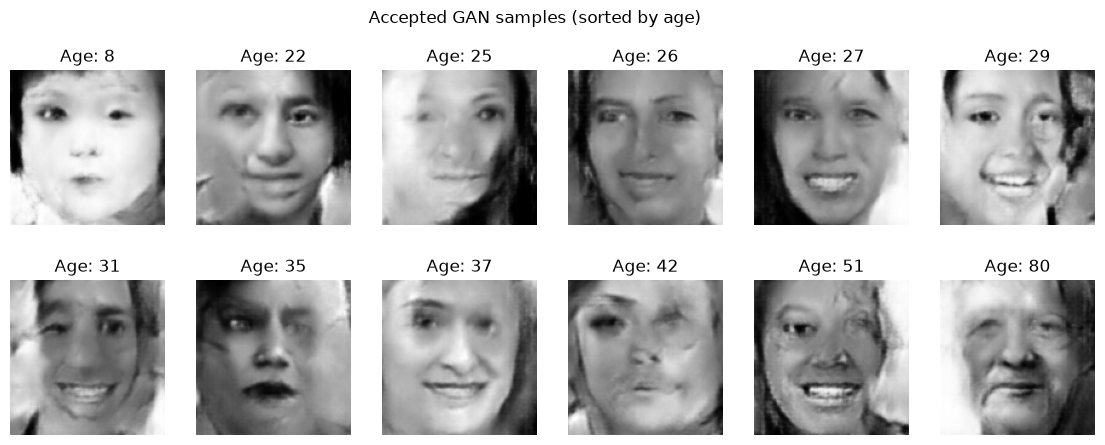

In [7]:
NUM_CANDIDATES = 4000
MAX_ERROR_YEARS = 5

target_ages = np.random.choice(y_train, NUM_CANDIDATES).astype(np.float32)
noise = tf.random.normal([NUM_CANDIDATES, NOISE_DIM])
fake = generator.predict([noise, target_ages.reshape(-1, 1)], batch_size=GAN_BATCH_SIZE, verbose=0)
fake_imgs = np.clip((fake + 1.0) * 127.5, 0, 255).astype(np.uint8)   # back to 0-255 like the real images

judge_pred = cnn_model.predict(fake_imgs.astype(np.float32), batch_size=64, verbose=0).ravel()
judge_err = denormalize_age(np.abs(judge_pred - target_ages))
keep = judge_err <= MAX_ERROR_YEARS

gan_imgs, gan_ages = fake_imgs[keep], target_ages[keep]
print(f"Mean age error of generated faces: {judge_err.mean():.2f} years")
print(f"Kept {keep.sum()} / {NUM_CANDIDATES} generated faces ({100 * keep.mean():.1f}%)")

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
order = np.argsort(gan_ages)
for ax, i in zip(axes.ravel(), order[np.linspace(0, len(order) - 1, 12).astype(int)]):
    ax.imshow(gan_imgs[i, :, :, 0], cmap="gray")
    ax.set_title(f"Age: {denormalize_age(gan_ages[i]):.0f}")
    ax.axis("off")
plt.suptitle("Accepted GAN samples (sorted by age)")
plt.show()

## 4. Model 2 – CNN + GAN augmentation

Augmented training data shape: (18370, 128, 128, 1)


Epoch 1/50


575/575 - 44s - 76ms/step - loss: 0.0173 - mae: 0.2157 - val_loss: 0.0354 - val_mae: 0.4028 - learning_rate: 0.0010


Epoch 2/50


575/575 - 40s - 70ms/step - loss: 0.0091 - mae: 0.1313 - val_loss: 0.0105 - val_mae: 0.1458 - learning_rate: 0.0010


...

575/575 - 40s - 69ms/step - loss: 0.0042 - mae: 0.0766 - val_loss: 0.0032 - val_mae: 0.0662 - learning_rate: 3.1250e-05


Epoch 32/50


575/575 - 39s - 68ms/step - loss: 0.0042 - mae: 0.0766 - val_loss: 0.0030 - val_mae: 0.0641 - learning_rate: 1.5625e-05


Epoch 33/50


575/575 - 40s - 70ms/step - loss: 0.0041 - mae: 0.0759 - val_loss: 0.0031 - val_mae: 0.0650 - learning_rate: 1.5625e-05


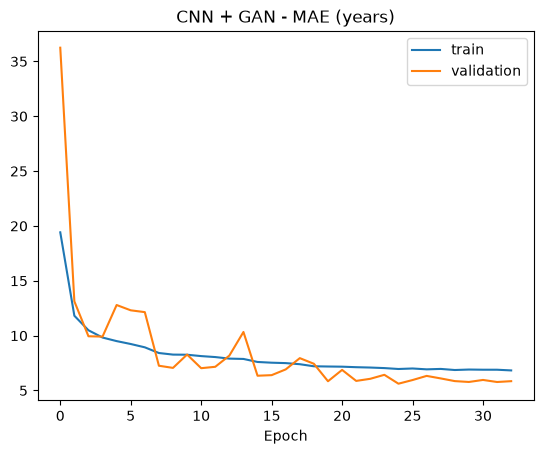

In [8]:
x_train_aug = np.concatenate([x_gray_train, gan_imgs], axis=0)
y_train_aug = np.concatenate([y_train, gan_ages], axis=0)
print("Augmented training data shape:", x_train_aug.shape)

tf.keras.utils.set_random_seed(SEED)
cnn_gan_model = build_cnn()
cnn_gan_history = cnn_gan_model.fit(
    make_dataset(x_train_aug, y_train_aug, training=True),
    validation_data=make_dataset(x_gray_val, y_val),
    epochs=50,
    callbacks=training_callbacks(),
    verbose=2,
)
plot_history(cnn_gan_history.history, "CNN + GAN")
cnn_gan_model.save("age_cnn_gan.keras")

## 5. Model 3 – Transfer learning (EfficientNetB0, RGB)

Stage 1 trains only the new head with the ImageNet backbone frozen; stage 2 fine-tunes the whole network with a
small learning rate.

Epoch 1/5


532/532 - 40s - 75ms/step - loss: 0.0106 - mae: 0.1469 - val_loss: 0.0060 - val_mae: 0.0971


Epoch 2/5


532/532 - 28s - 52ms/step - loss: 0.0070 - mae: 0.1092 - val_loss: 0.0058 - val_mae: 0.0960


Epoch 3/5


...

532/532 - 106s - 198ms/step - loss: 0.0015 - mae: 0.0420 - val_loss: 0.0025 - val_mae: 0.0548 - learning_rate: 1.2500e-05


Epoch 38/40


532/532 - 105s - 197ms/step - loss: 0.0015 - mae: 0.0419 - val_loss: 0.0025 - val_mae: 0.0549 - learning_rate: 1.2500e-05


Epoch 39/40


532/532 - 105s - 197ms/step - loss: 0.0015 - mae: 0.0416 - val_loss: 0.0026 - val_mae: 0.0552 - learning_rate: 1.2500e-05


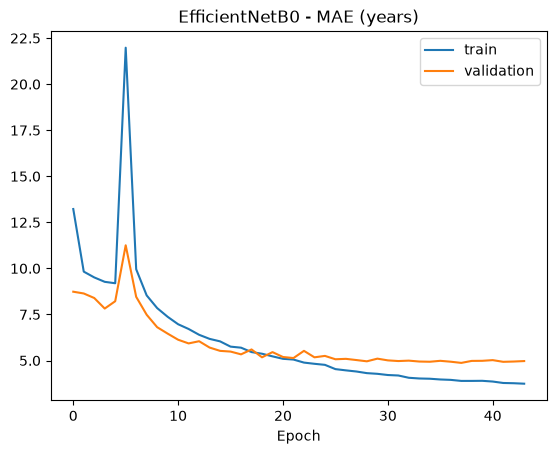

In [9]:
def build_efficientnet():
    base = tf.keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                                input_shape=(IMG_SIZE, IMG_SIZE, 3))
    inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augmentation()(inp)
    x = base(x, training=False)          # EfficientNet expects 0-255 input; BatchNorm stays in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1)(x)
    return models.Model(inp, out), base

tf.keras.utils.set_random_seed(SEED)
effnet_model, effnet_base = build_efficientnet()
rgb_train_ds = make_dataset(x_rgb_train, y_train, training=True)
rgb_val_ds = make_dataset(x_rgb_val, y_val)

# Stage 1: frozen backbone
effnet_base.trainable = False
effnet_model.compile(optimizer=optimizers.Adam(1e-3), loss=tf.keras.losses.Huber(delta=0.1), metrics=["mae"])
h1 = effnet_model.fit(rgb_train_ds, validation_data=rgb_val_ds, epochs=5, verbose=2)

# Stage 2: fine-tune everything
effnet_base.trainable = True
effnet_model.compile(optimizer=optimizers.Adam(1e-4), loss=tf.keras.losses.Huber(delta=0.1), metrics=["mae"])
h2 = effnet_model.fit(rgb_train_ds, validation_data=rgb_val_ds, epochs=40,
                      callbacks=training_callbacks(patience=6), verbose=2)

plot_history({k: h1.history[k] + h2.history[k] for k in ["mae", "val_mae"]}, "EfficientNetB0")
effnet_model.save("age_efficientnet.keras")

## 6. Results on the test set

Model             Val MAE  Test MAE  Test RMSE   (years)
CNN                  6.03      6.16       8.12
CNN + GAN            5.62      5.83       8.05
EfficientNetB0       4.87      4.97       7.07

Test MAE by age group (years):
Model               0-12   13-19   20-29   30-39   40-49   50-59   60-90
CNN                 8.63    5.81    3.91    5.40    6.85    8.24    8.68
CNN + GAN           4.28    4.71    3.74    5.79    7.55    8.98   10.14
EfficientNetB0      2.22    4.92    3.69    5.59    6.76    7.44    7.37


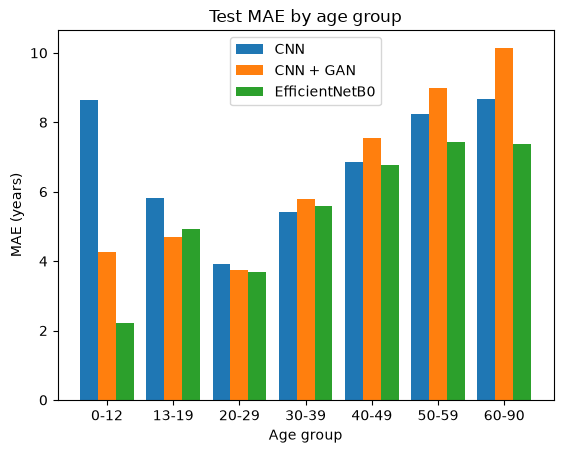


Best model (by validation MAE): EfficientNetB0


In [10]:
results = {
    "CNN":            (cnn_model,     x_gray_test, x_gray_val),
    "CNN + GAN":      (cnn_gan_model, x_gray_test, x_gray_val),
    "EfficientNetB0": (effnet_model,  x_rgb_test,  x_rgb_val),
}
scores = {name: evaluate_model(m, x_te, y_test) for name, (m, x_te, _) in results.items()}
val_mae = {name: evaluate_model(m, x_va, y_val)["MAE"] for name, (m, _, x_va) in results.items()}

print(f"{'Model':<16}{'Val MAE':>9}{'Test MAE':>10}{'Test RMSE':>11}   (years)")
for name, s in scores.items():
    print(f"{name:<16}{val_mae[name]:>9.2f}{s['MAE']:>10.2f}{s['RMSE']:>11.2f}")

print("\nTest MAE by age group (years):")
print(f"{'Model':<16}" + "".join(f"{g:>8}" for g in scores["CNN"]["groups"]))
for name, s in scores.items():
    print(f"{name:<16}" + "".join(f"{v:>8.2f}" for v in s["groups"].values()))

group_names = list(scores["CNN"]["groups"])
width = 0.27
for i, (name, s) in enumerate(scores.items()):
    plt.bar(np.arange(len(group_names)) + (i - 1) * width, list(s["groups"].values()), width, label=name)
plt.xticks(np.arange(len(group_names)), group_names)
plt.xlabel("Age group")
plt.ylabel("MAE (years)")
plt.title("Test MAE by age group")
plt.legend()
plt.show()

# The final model is chosen on the validation set, not the test set
best_name = min(val_mae, key=val_mae.get)
best_model, best_x_test, _ = results[best_name]
print(f"\nBest model (by validation MAE): {best_name}")

In [ ]:
# Export everything the web app needs into models/ (see models/README.md)
import json, shutil

MODELS_DIR = "models"
os.makedirs(MODELS_DIR, exist_ok=True)
for f in ["age_cnn.keras", "age_cnn_gan.keras", "age_efficientnet.keras", "gan_generator.keras"]:
    shutil.copy(f, os.path.join(MODELS_DIR, f))

keys = {"CNN": "cnn", "CNN + GAN": "cnn_gan", "EfficientNetB0": "efficientnet"}
metrics = {
    "dataset": {"name": "UTKFace (aligned & cropped)", "url": "https://susanqq.github.io/UTKFace/",
                "age_range": [0, MAX_AGE], "train": len(y_train), "val": len(y_val), "test": len(y_test)},
    "models": {keys[n]: {"val_mae": round(float(val_mae[n]), 2), "test_mae": round(float(s["MAE"]), 2),
                         "test_rmse": round(float(s["RMSE"]), 2),
                         "mae_by_age_group": {g: round(float(v), 2) for g, v in s["groups"].items()}}
               for n, s in scores.items()},
    "best_model": keys[best_name],
    "gan": {"type": "Conditional DCGAN with projection discriminator", "noise_dim": NOISE_DIM,
            "output": "128×128 grayscale", "candidates": NUM_CANDIDATES, "accepted": int(keep.sum()),
            "mean_age_error_years": round(float(judge_err.mean()), 2)},
}
with open(os.path.join(MODELS_DIR, "metrics.json"), "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print("Wrote", os.path.join(MODELS_DIR, "metrics.json"))

## 7. Predictions

True Age: 29, Predicted Age: 29.4


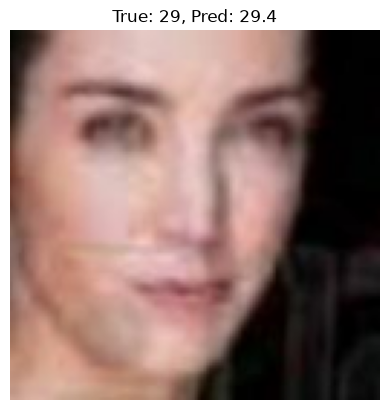

True Age: 61, Predicted Age: 48.7


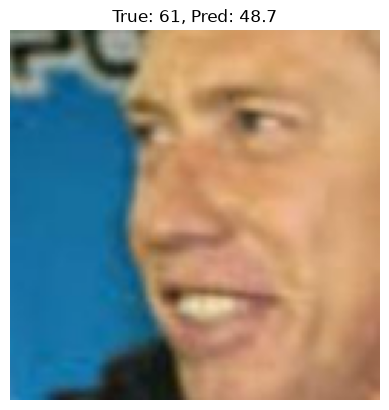

True Age: 2, Predicted Age: 2.4


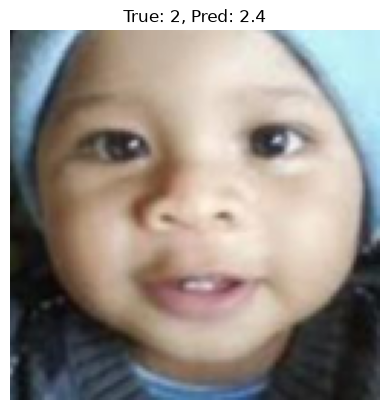

In [11]:
def test_random_dataset_sample(model, x_data, y_data):
    idx = np.random.randint(0, len(x_data))
    img = x_data[idx]
    true_age = denormalize_age(y_data[idx])
    pred_age = denormalize_age(model.predict(img[None].astype(np.float32), verbose=0)[0][0])
    print(f"True Age: {true_age:.0f}, Predicted Age: {pred_age:.1f}")
    plt.imshow(img.squeeze(), cmap="gray" if img.shape[-1] == 1 else None)
    plt.title(f"True: {true_age:.0f}, Pred: {pred_age:.1f}")
    plt.axis("off")
    plt.show()

for _ in range(3):
    test_random_dataset_sample(best_model, best_x_test, y_test)

In [12]:
# YuNet face detector (OpenCV) – crops the face like the UTKFace images before predicting
FACE_DETECTOR_PATH = "face_detection_yunet_2023mar.onnx"
if not os.path.exists(FACE_DETECTOR_PATH):
    import urllib.request
    urllib.request.urlretrieve(
        "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx",
        FACE_DETECTOR_PATH)

# Margins (left, top, right, bottom) as a fraction of the detected box. Measured with YuNet on 1,000
# UTKFace images, so uploaded photos are framed the same way as the training images.
FACE_MARGINS = (0.09, 0.0, 0.08, 0.02)

def crop_face(img, margins=FACE_MARGINS):
    h, w = img.shape[:2]
    detector = cv2.FaceDetectorYN.create(FACE_DETECTOR_PATH, "", (w, h), score_threshold=0.7)
    _, faces = detector.detect(img)
    if faces is None:
        return img, False
    x, y, fw, fh = faces[np.argmax(faces[:, 2] * faces[:, 3]), :4]   # largest face
    left, top, right, bottom = margins
    x0, y0 = int(max(0, x - left * fw)), int(max(0, y - top * fh))
    x1, y1 = int(min(w, x + fw + right * fw)), int(min(h, y + fh + bottom * fh))
    return img[y0:y1, x0:x1], True

def predict_custom_image(model, image_path):
    img = cv2.imread(image_path)
    face, found = crop_face(img)
    face = cv2.resize(face, (IMG_SIZE, IMG_SIZE))
    if model.input_shape[-1] == 1:
        face = cv2.cvtColor(face, cv2.COLOR_BGR2GRAY)[..., None]
    else:
        face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

    pred_age = denormalize_age(model.predict(face[None].astype(np.float32), verbose=0)[0][0])

    plt.imshow(face.squeeze(), cmap="gray" if face.shape[-1] == 1 else None)
    plt.title(f"Predicted Age: {pred_age:.1f}" + ("" if found else " (no face detected)"))
    plt.axis("off")
    plt.show()
    return pred_age

In [13]:
# Put the path of any face image here
custom_image = "test.jpg"
if os.path.exists(custom_image):
    predicted = predict_custom_image(best_model, custom_image)
    print("Predicted Age:", predicted)